# Лабораторна 1. Основні бібліотеки. Лінійні моделі навчання.

В цій лабораторній роботі студенти:
- ознайомлюються з сервісом Colab;
- ознайомлюються з базовими бібліотеками для машинного навчання;
- тренують неглибокі лінійні моделі машинного навчання на базі простих регресій: лінійна, логістична, поліноміальна.

## 0. Налаштування середовища

### 0.0. Імпортуємо залежності

In [1]:
import sys
import os
import random
import numpy as np
import torch
import pandas as pd
import matplotlib.pyplot as plt

### 0.1. Перевіряємо чи ми точно в Colab

In [2]:
IN_COLAB = "google.colab" in sys.modules
print("Running in Colab:", IN_COLAB)

assert IN_COLAB, f"Ця лаба має вокинуватися в Google Colab (https://colab.research.google.com/)"

Running in Colab: True


### 0.2. Фіксуємо всі джерела випадковості.
На GPU повна детермінованість трохи сповільнює тренування
(`cudnn.deterministic = True` вимикає частину швидких алгоритмів) —
тут це не критично, адже дані й модель дрібні.

In [3]:
SEED = 42

def set_seed(seed: int = SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

**Вправа 1.** Скористайся вбудованим модулем `random`. Спробуй `random.randint(1, 100)` і `random.shuffle()` на списку — випадковість буває не лише в числі, а й у перестановці. Згенеруй обома способами двічі ДО виклику `set_seed()` — переконайся, що результати різні. Потім ще двічі **ПІСЛЯ** з викликом set_seed() після кожної генерації і потім ще двічі **без проміжного виклику** `set_seed()`.

Після клітинки з кодом створи клітинку з маркдауном і поясни що відбувається після `set_seed()` і як це проявляється в результатах виконання коду.

In [4]:
numbers = list(range(10))  # список для shuffle

# TODO: двічі ДО set_seed() -- наприклад random.randint(1, 100) і random.shuffle(numbers)

print("До set_seed():")

print(random.randint(1, 100))
random.shuffle(numbers)
print(numbers)

print(random.randint(1, 100))
random.shuffle(numbers)
print(numbers)


set_seed()
print("Seed зафіксовано:", SEED)

# TODO: тепер двічі ПІСЛЯ set_seed() -- виклич set_seed() перед КОЖНИМ окремим генеруванням

set_seed()
print(random.randint(1, 100))
random.shuffle(numbers)
print(numbers)

set_seed()
print(random.randint(1, 100))
random.shuffle(numbers)
print(numbers)


# TODO: тепер ще двічі без проміжних викликів set_seed()

print(random.randint(1, 100))
random.shuffle(numbers)
print(numbers)

print(random.randint(1, 100))
random.shuffle(numbers)
print(numbers)

До set_seed():
100
[5, 4, 3, 2, 8, 0, 1, 6, 7, 9]
81
[6, 3, 8, 7, 5, 9, 0, 2, 4, 1]
Seed зафіксовано: 42
82
[2, 7, 8, 4, 9, 0, 1, 5, 6, 3]
82
[5, 4, 8, 6, 0, 1, 3, 9, 2, 7]
76
[0, 6, 8, 7, 1, 4, 9, 2, 5, 3]
92
[4, 6, 3, 0, 8, 1, 2, 7, 9, 5]


### Пояснення

До `set_seed()` результати кожного разу різні, тому що генератор випадкових чисел працює у своєму стані.

Після `set_seed()` ми задаємо однакове початкове значення для генератора. Тому якщо перед кожною генерацією знову викликати `set_seed()`, то результати будуть однакові. Це видно і для `randint()`, і для `shuffle()`.

А коли `set_seed()` більше не викликається між генераціями, генератор продовжує працювати далі, тому результати знову стають різними.

Тобто `set_seed()` потрібен для того, щоб можна було отримувати однакову послідовність випадкових значень.

### 0.3. Використовуємо лише CPU (в цій лабі)
На Colab зазвичай є безкоштовний GPU (T4), але для лінійної регресії
на кількасот точок CPU часто не повільніший — виграш GPU з'їдає пересилання
даних на пристрій і назад щоепохи. Тому нижче свідомо тренуємось на CPU.

In [5]:
device_available = torch.device("cuda" if torch.cuda.is_available() else "cpu")
device = torch.device("cpu")

print("Доступний пристрій :", device_available)
print("Використовуємо     :", device)
if device_available.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

assert device.type == "cpu", f"Ця лаба має виконуватися на CPU, а не на GPU ({device})"

Доступний пристрій : cuda
Використовуємо     : cpu
GPU: Tesla T4


**Вправа 2.** Встанови CPU рантайм. Запусти комірку вище і зроби скріншот виводу. Потім у Colab зміни рантайм на GPU, перезапусти всі комірки від початку. Знову зроби скріншот тієї самої комірки. Збережи обидва скріншоти — пізніше завантажиш їх на GitHub разом зі здачею лаби.

### 0.4. Монтуємо Google Drive

Сесія Colab обмежена в часі й може скинутись — усе в `/content` зникає разом
з нею. Монтуємо Drive, щоб чекпоінт моделі й логи TensorBoard пережили
перезапуск.

In [6]:
from google.colab import drive
drive.mount("/content/drive")
ARTIFACT_DIR = "/content/drive/MyDrive/ai_systems/lab1"


os.makedirs(ARTIFACT_DIR, exist_ok=True)
RUNS_DIR = os.path.join(ARTIFACT_DIR, "runs")
os.makedirs(RUNS_DIR, exist_ok=True)
print("Артефакти зберігаються в:", ARTIFACT_DIR)


Mounted at /content/drive
Артефакти зберігаються в: /content/drive/MyDrive/ai_systems/lab1


---
## 1. Ознайомлення з бібліотеками

Кілька дуже простих вправ на NumPy, pandas, PyTorch і Matplotlib — щоб мати
спільну базу перед тим, як усі чотири підуть у хід одночасно.

### 1.1. NumPy

Документація: https://numpy.org/doc/stable/

**Вправа 3.** Створи масив форми 3×4, заповнений нулями (`np.zeros`), і ще один такої самої форми, заповнений числом 7 (`np.full`). Виведи форму (`.shape`) і тип даних (`.dtype`) обох.

In [9]:
zeros_arr = np.zeros((3, 4))
sevens_arr = np.full((3, 4), 7)


print(zeros_arr, zeros_arr.shape if zeros_arr is not None else None, zeros_arr.dtype if zeros_arr is not None else None)
print(sevens_arr, sevens_arr.shape if sevens_arr is not None else None, sevens_arr.dtype if sevens_arr is not None else None)


[[0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]] (3, 4) float64
[[7 7 7 7]
 [7 7 7 7]
 [7 7 7 7]] (3, 4) int64


**Вправа 4.** Створи масив від 0 до 20 із кроком 2 через `np.arange`, і масив із 5 рівномірно розподілених точок від 0 до 1 через `np.linspace`. Виведи обидва.

In [10]:
arange_arr = np.arange(0, 20, 2)
linspace_arr = np.linspace(0, 1, 5)


print(arange_arr)
print(linspace_arr)


[ 0  2  4  6  8 10 12 14 16 18]
[0.   0.25 0.5  0.75 1.  ]


**Вправа 5.** Створи одиничну матрицю 4×4 (`np.eye`) і випадковий масив цілих чисел форми 3×3 у діапазоні [0, 10) (`np.random.randint`). Виведи `.ndim` обох масивів.

In [11]:
identity = np.eye(4)
random_ints = np.random.randint(0, 10, size=(3, 3))

print(identity)
print(random_ints)
print('ndim identity:', identity.ndim)
print('ndim random_ints:', random_ints.ndim)


[[1. 0. 0. 0.]
 [0. 1. 0. 0.]
 [0. 0. 1. 0.]
 [0. 0. 0. 1.]]
[[6 3 7]
 [4 6 9]
 [2 6 7]]
ndim identity: 2
ndim random_ints: 2


**Вправа 6.** Маєш масив оцінок студентів. Порахуй середнє, стандартне відхилення і z-normalized версію масиву — без циклів.

In [12]:
scores = np.array([78, 85, 92, 67, 90, 74, 88, 95, 60, 82])

# TODO: порахувати mean, std і z_scores = (scores - mean) / std
mean = scores.mean()
std = scores.std()
z_scores = (scores - mean) / std

print("Середнє:", mean, " Std:", std)
print("Z-scores:", z_scores)


Середнє: 81.1  Std: 10.76522178127325
Z-scores: [-0.28796434  0.36227772  1.01251978 -1.30977329  0.82673633 -0.65953123
  0.64095289  1.29119495 -1.96001536  0.08360255]


**Вправа 7.** Маєш 1D масив із 12 чисел. Перетвори його на матрицю 3×4 і порахуй суму кожного рядка та кожного стовпця.

In [15]:
arr = np.arange(1, 13)

# TODO: перетворити arr на матрицю 3x4 (reshape), порахувати суми по рядках
# (axis=1) і по стовпцях (axis=0)
matrix = arr.reshape(3,4)
row_sums = matrix.sum(axis=0)
col_sums = matrix.sum(axis=1)

print(matrix)
print("Сума по рядках:  ", row_sums)
print("Сума по стовпцях:", col_sums)


[[ 1  2  3  4]
 [ 5  6  7  8]
 [ 9 10 11 12]]
Сума по рядках:   [15 18 21 24]
Сума по стовпцях: [10 26 42]


### 1.2. pandas

Документація: https://pandas.pydata.org/docs/

**Вправа 8.** Створи таблицю студентів з оцінками. Виведи тільки тих, хто набрав більше 80 балів, відсортованих за спаданням оцінки.

In [26]:
df = pd.DataFrame({'Name': ['Alice', 'Bob', 'Aritra', 'Ivan', 'Oleg'],
                   'Score': [67, 70, 86, 90, 81]}) # додай тут дані для DataFrame

# TODO: відфільтрувати score > 80 і відсортувати за score за спаданням
top = df[df['Score'] > 80].sort_values('Score', ascending=False)
print(top)


     Name  Score
3    Ivan     90
2  Aritra     86
4    Oleg     81


**Вправа 9.** Додай колонку `grade`: `A` якщо `score >= 90`, `B` якщо `score >= 75`, інакше `C`.

In [30]:
# TODO: додати колонку "grade"
# умови: score >= 90 -> "A", score >= 75 -> "B", інакше -> "C"
df['grade'] = np.select(
    [df['Score'] >= 90, df['Score'] >= 75],
    ['A', 'B'],
    default='C'
)
print(df)


     Name  Score grade
0   Alice     67     C
1     Bob     70     C
2  Aritra     86     B
3    Ivan     90     A
4    Oleg     81     B


### 1.3. PyTorch

Документація: https://pytorch.org/docs/stable/index.html

**Вправа 10.** Створи тензор форми 2×3, заповнений нулями (`torch.zeros`), і ще один такої самої форми, заповнений числом 7 (`torch.full`). Виведи форму (`.shape`) і тип даних (`.dtype`) обох.

In [35]:
zeros_t = torch.zeros((2, 3))
sevens_t = torch.full((2, 3), 7)


print(zeros_t)
print(sevens_t)

print(f"Shape of tensor zeros: {zeros_t.shape}")
print(f"Datatype of tensor zeros: {zeros_t.dtype}")
print(f"Shape of tensor sevens: {sevens_t.shape}")
print(f"Datatype of tensor sevens: {sevens_t.dtype}")

tensor([[0., 0., 0.],
        [0., 0., 0.]])
tensor([[7, 7, 7],
        [7, 7, 7]])
Shape of tensor zeros: torch.Size([2, 3])
Datatype of tensor zeros: torch.float32
Shape of tensor sevens: torch.Size([2, 3])
Datatype of tensor sevens: torch.int64


**Вправа 11.** Створи тензор від 0 до 20 із кроком 2 через `torch.arange`, і тензор із 5 рівномірно розподілених точок від 0 до 1 через `torch.linspace`.

In [36]:
arange_t = torch.arange(0, 20, 2)
linspace_t = torch.linspace(0, 1, 5)


print(arange_t)
print(linspace_t)


tensor([ 0,  2,  4,  6,  8, 10, 12, 14, 16, 18])
tensor([0.0000, 0.2500, 0.5000, 0.7500, 1.0000])


**Вправа 12.** Створи тензор напряму зі списку — `torch.tensor([[1, 2], [3, 4]])` — і випадковий тензор форми 3×3 через `torch.rand`. Виведи `.shape`, `.dtype` і `.ndim` обох.

In [39]:
from_list = torch.tensor([[1, 2], [3, 4]])
random_t = torch.rand(3, 3)


print(from_list, from_list.shape, from_list.dtype, from_list.ndim)
print(random_t, random_t.shape, random_t.dtype, random_t.ndim)


tensor([[1, 2],
        [3, 4]]) torch.Size([2, 2]) torch.int64 2
tensor([[0.2666, 0.6274, 0.2696],
        [0.4414, 0.2969, 0.8317],
        [0.1053, 0.2695, 0.3588]]) torch.Size([3, 3]) torch.float32 2


**Вправа 13.** Створи тензор `x = 5.0` з `requires_grad=True`, порахуй `y = x**2` і перевір автоматичний градієнт проти аналітичного ($dy/dx = 2x$).

In [42]:
n = 5.0

x = torch.tensor(n, requires_grad=True)
y = x ** 2
y.backward()
# надрукувати x.grad.item() і порівняти з 2 * n

print('Автоматичний градієнт:', x.grad.item())
print('Аналітичний градієнт:', 2 * n)

Автоматичний градієнт: 10.0
Аналітичний градієнт: 10.0


**Вправа 14.** Знайди $x$, який мінімізує $(x-3)^2 + 5$ — не аналітично, а градієнтним спуском: `x` як параметр з `requires_grad=True`, без жодної моделі.

In [44]:
x = torch.tensor(0.0, requires_grad=True)
lr = 0.1

# TODO: цикл градієнтного спуску (20 кроків):
for _ in range(20):
    loss = (x - 3) ** 2 + 5
    loss.backward()
    with torch.no_grad():
        x -= lr * x.grad
    x.grad.zero_()

print(f"x = {x.item():.4f}  (мінімум у x=3)")


x = 2.9654  (мінімум у x=3)


### 1.4. Matplotlib

Документація: https://matplotlib.org/stable/index.html

**Вправа 15.** Побудуй графік функції $y = \sin(x)$ на проміжку $[0, 2\pi]$.

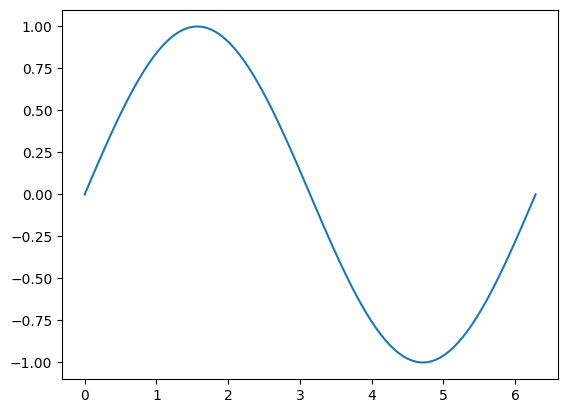

In [46]:
xs = np.linspace(0, 2*np.pi, 100)
plt.plot(xs, np.sin(xs))
plt.show()


**Вправа 16.** На одному графіку познач дві групи точок різними кольорами і додай легенду.

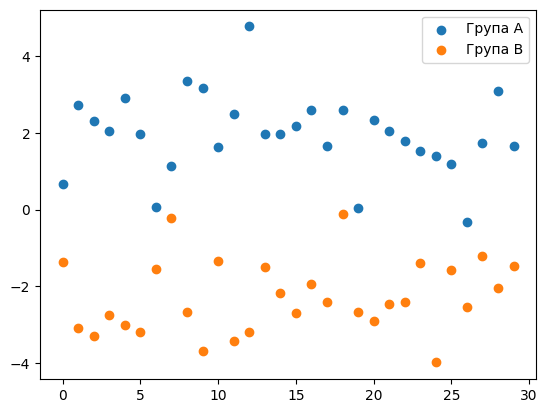

In [50]:
group_a = np.random.randn(30) + 2
group_b = np.random.randn(30) - 2

# TODO: scatter обох груп різними кольорами (color="C0"/"C1", label=...),

plt.scatter(np.arange(30), group_a, color='C0', label='Група A')
plt.scatter(np.arange(30), group_b, color='C1', label='Група B')

plt.legend()
plt.show()


---
## Завдання 1. Лінійна регресія

Тренуємо базовий пайплайн на простій лінійній регресії з одним параметром.

$$y = w \cdot x + b + \varepsilon, \quad \varepsilon \sim \mathcal{N}(0, 1)$$

In [51]:
TASK1_TRUE_W = 2.0
TASK1_TRUE_B = 1.0
TASK1_N = 300

x1 = torch.empty(TASK1_N, 1).uniform_(-5, 5)
noise = 1.0 * torch.randn(TASK1_N, 1)
y1 = TASK1_TRUE_W * x1 + TASK1_TRUE_B + noise

**Вправа 17.** Перш ніж будувати модель — подивись на самі дані.

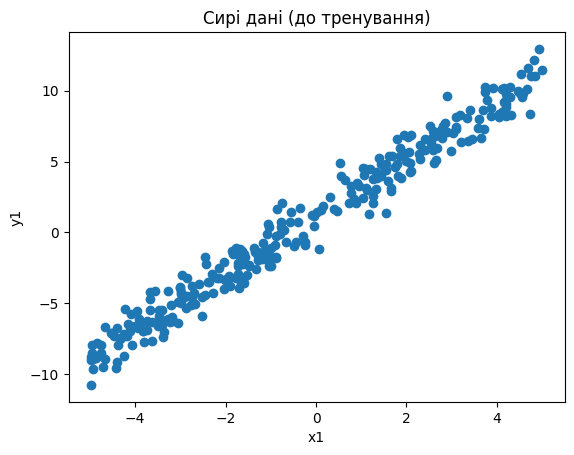

In [53]:
# TODO: Точкова діаграма (scatter plot) з вісями x1 та y1, підпис осей (xlabel/ylabel), заголовок
# "Сирі дані (до тренування)"
plt.scatter(x1, y1)
plt.xlabel("x1")
plt.ylabel("y1")
plt.title("Сирі дані (до тренування)")
plt.show()

**Вправа 18.** Розбий дані на train/val/test (70/15/15). Перемішай дані перед зрізом, інакше спліт вийде не випадковим.

In [54]:
# TODO: перемішати x1/y1 через torch.randperm(TASK1_N), розбити на
# train/val/test у пропорції 70/15/15
perm = torch.randperm(TASK1_N)
x_shuffled, y_shuffled = x1[perm], y1[perm]
n_train = int(0.70 * TASK1_N)
n_val = int(0.15 * TASK1_N)
x_train1, y_train1 = x_shuffled[:n_train], y_shuffled[:n_train]
x_val1, y_val1 = x_shuffled[n_train:n_train+n_val], y_shuffled[n_train:n_train+n_val]
x_test1, y_test1 = x_shuffled[n_train+n_val:], y_shuffled[n_train+n_val:]
print(f"train/val/test: {len(x_train1)}/{len(x_val1)}/{len(x_test1)}")


train/val/test: 210/45/45


**Вправа 19.** Нижче — готовий цикл навчання, кожен крок підписаний окремо. Просто запусти обидві комірки й подивись, як модель наближається до `true` за 100 епох (знімки кожні 30 епох).

In [55]:
task1_model = torch.nn.Linear(in_features=1, out_features=1)
optimizer = torch.optim.SGD(task1_model.parameters(), lr=0.05)
loss_fn = torch.nn.MSELoss()

x_line = torch.linspace(-5, 5, 100).unsqueeze(1)  # сітка для візуалізації лінії
snapshots = []  # (epoch, w, b, y_line_pred) кожні 30 епох

for epoch in range(100):
    # обнулити градієнти з попереднього кроку
    optimizer.zero_grad()
    # forward -- прогноз моделі на поточних w, b
    y_pred = task1_model(x_train1)
    # loss -- наскільки прогноз відрізняється від y_train1
    loss = loss_fn(y_pred, y_train1)
    # backward -- градієнти loss за w і b
    loss.backward()
    # крок оптимізатора -- оновити w і b
    optimizer.step()

    if epoch % 30 == 0 or epoch == 99:
        with torch.no_grad():
            y_line_pred = task1_model(x_line)
        snapshots.append((epoch, task1_model.weight.item(), task1_model.bias.item(), y_line_pred))
        print(f"epoch {epoch:4d}  loss={loss.item():.6f}  "
              f"w={task1_model.weight.item():.4f} (true {TASK1_TRUE_W})  "
              f"b={task1_model.bias.item():.4f} (true {TASK1_TRUE_B})")


epoch    0  loss=52.979351  w=1.6628 (true 2.0)  b=-0.2247 (true 1.0)
epoch   30  loss=0.861695  w=2.0045 (true 2.0)  b=1.1035 (true 1.0)
epoch   60  loss=0.857253  w=2.0060 (true 2.0)  b=1.1611 (true 1.0)
epoch   90  loss=0.857244  w=2.0061 (true 2.0)  b=1.1636 (true 1.0)
epoch   99  loss=0.857244  w=2.0061 (true 2.0)  b=1.1636 (true 1.0)


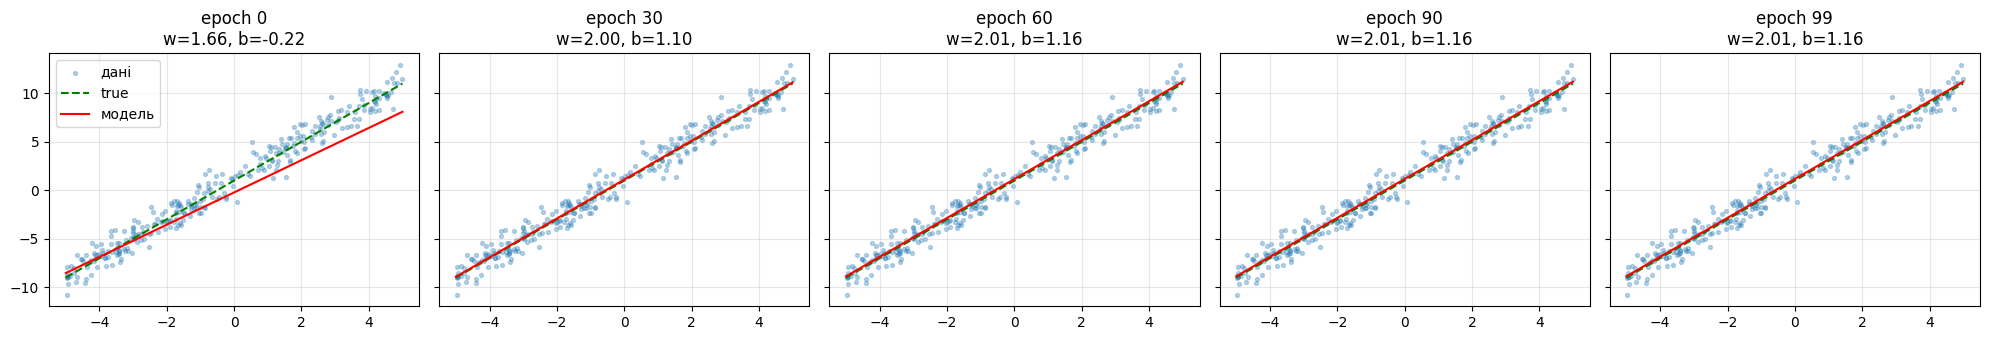

In [56]:
with torch.no_grad():
    y_line_true = TASK1_TRUE_W * x_line + TASK1_TRUE_B

fig, axes = plt.subplots(1, len(snapshots), figsize=(4 * len(snapshots), 3.5), sharey=True)
for ax, (epoch, w, b, y_line_pred) in zip(axes, snapshots):
    ax.scatter(x1.numpy(), y1.numpy(), s=8, alpha=0.3, label="дані")
    ax.plot(x_line.numpy(), y_line_true.numpy(), "g--", label="true")
    ax.plot(x_line.numpy(), y_line_pred.numpy(), "r-", label="модель")
    ax.set_title(f"epoch {epoch}\nw={w:.2f}, b={b:.2f}")
    ax.grid(alpha=0.3)
axes[0].legend()
plt.tight_layout()
plt.show()


**Вправа 20.** Придумай власний напів-реальний сценарій лінійної залежності
(наприклад: кількість з'їдених пачок чіпсів на тиждень → індекс маси тіла;
години сну → продуктивність; щось своє). У markdown-комірці перед кодом
опиши сценарій: яку залежність ти
закладаєш ($w$, $b$) і чому саме такі значення видались тобі правдоподібними.
Згенеруй дані з шумом, збережи їх у CSV файл (за зразком відповідної частини лекції)
і натренуй лінійну регресію за тим самим патерном — спліт, цикл навчання, перевірка на test.
Організуй код тренування у логічні перевикористовувані функції.

**Вправа 21.** Збережи натреновану модель на своєму гугл диску у файлі з назвою `model.pt`.
Збережений файл потрібно буде також здати разом з лабою.

Буду досліджувати залежність кількості пройдених кілометрів від витрати пального.
Я візьму за приклад свій автомобіль Volkswagen Golf 5 з бензиновим двигуном 1.6.

Для автомобіля візьмемо середню витрату 7.5 літра на 100 км.

Тому коефіцієнт `w` буде дорівнювати `0.075`, оскільки:

`7.5 / 100 = 0.075`

Початкове значення `b` візьмемо рівним `0`, тому що без пройдених кілометрів витрата пального за нашою спрощеною моделлю дорівнює нулю.

Формула залежності:

`y = 0.075x`

де `x` — кількість пройдених кілометрів, а `y` — витрата пального в літрах.

У реальному житті витрата може відрізнятися через швидкість, затори, стиль водіння(а я люблю трохи поганяти) та стан автомобіля, тому до даних додамо випадковий шум.

In [61]:
set_seed()

GOLF_TRUE_W = 0.075
GOLF_TRUE_B = 0.0
GOLF_N = 240

# Генеруємо дані
kilometers = torch.empty(GOLF_N, 1).uniform_(0, 300)
noise = 0.5 * torch.randn(GOLF_N, 1)

fuel_target = GOLF_TRUE_W * kilometers + GOLF_TRUE_B + noise

# Зберігаємо дані у CSV
dataset = pd.DataFrame({
    "kilometers": kilometers.squeeze().numpy(),
    "fuel_liters": fuel_target.squeeze().numpy()
})

dataset.to_csv(os.path.join(ARTIFACT_DIR, "dataset.csv"), index=False)

print(dataset.head())
print("CSV збережено:", os.path.join(ARTIFACT_DIR, "dataset.csv"))


# Розбиваємо дані на train/val/test (70/15/15)
perm = torch.randperm(GOLF_N)

km_shuffled = kilometers[perm]
fuel_shuffled = fuel_target[perm]

n_train = int(0.70 * GOLF_N)
n_val = int(0.15 * GOLF_N)

km_train = km_shuffled[:n_train]
fuel_train = fuel_shuffled[:n_train]

km_val = km_shuffled[n_train:n_train+n_val]
fuel_val = fuel_shuffled[n_train:n_train+n_val]

km_test = km_shuffled[n_train+n_val:]
fuel_test = fuel_shuffled[n_train+n_val:]

print(f"train/val/test: {len(km_train)}/{len(km_val)}/{len(km_test)}")


# Функція навчання лінійної моделі
def train_linear_model(x_train, y_train, epochs=500, lr=0.00001):
    model = torch.nn.Linear(in_features=1, out_features=1)
    optimizer = torch.optim.SGD(model.parameters(), lr=lr)
    loss_fn = torch.nn.MSELoss()

    history = []

    for epoch in range(epochs):
        optimizer.zero_grad()

        y_pred = model(x_train)

        loss = loss_fn(y_pred, y_train)

        loss.backward()

        optimizer.step()

        history.append(loss.item())

    return model, history

# Навчаємо модель
model20, history20 = train_linear_model(
    km_train,
    fuel_train
)


# Перевірка на validation та test
with torch.no_grad():
    val_pred = model20(km_val)
    test_pred = model20(km_test)

    val_mse = torch.mean((val_pred - fuel_val) ** 2).item()
    test_mse = torch.mean((test_pred - fuel_test) ** 2).item()

print(f"Validation MSE: {val_mse:.6f}")
print(f"Test MSE: {test_mse:.6f}")

print(f"Вивчена модель: w={model20.weight.item():.4f}, "
      f"b={model20.bias.item():.4f}")

print(f"Справжні значення: w={GOLF_TRUE_W}, b={GOLF_TRUE_B}")

   kilometers  fuel_liters
0  264.680786    19.386494
1  274.501190    20.725685
2  114.859131     8.344997
3  287.791687    21.815668
4  117.134460     8.349140
CSV збережено: /content/drive/MyDrive/ai_systems/lab1/dataset.csv
train/val/test: 168/36/36
Validation MSE: 0.273826
Test MSE: 0.300703
Вивчена модель: w=0.0765, b=-0.2546
Справжні значення: w=0.075, b=0.0


**Збереження моделі**

In [62]:
model_path = os.path.join(ARTIFACT_DIR, "model.pt")
torch.save(model20.state_dict(), model_path)
print("Модель збережено:", model_path)


Модель збережено: /content/drive/MyDrive/ai_systems/lab1/model.pt


**Вправа 22.** Встанови [Gradio](https://gradio.app/)
```
!pip install -q gradio
import gradio as gr
```
Завантаж свою модель, збережену в попередній вправі і створи інтерактивну аппку.

In [63]:
!pip install -q gradio

In [64]:
import gradio as gr

In [65]:
# Створюємо таку саму модель
model = torch.nn.Linear(in_features=1, out_features=1)

# Завантажуємо збережені параметри
model.load_state_dict(
    torch.load(os.path.join(ARTIFACT_DIR, "model.pt"))
)

model.eval()


# Функція прогнозування
def predict_fuel(kilometers):
    x = torch.tensor([[float(kilometers)]])

    with torch.no_grad():
        prediction = model(x)

    return round(prediction.item(), 2)


# Створюємо Gradio app
app = gr.Interface(
    fn=predict_fuel,
    inputs=gr.Number(
        label="Кількість пройдених кілометрів",
        value=100
    ),
    outputs=gr.Number(
        label="Прогнозована витрата пального, л"
    ),
    title="Прогноз витрати пального Volkswagen Golf 5",
    description="Введіть кількість кілометрів, щоб отримати прогнозовану витрату пального."
)

app.launch()

It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://2b72d8d149a6d85b7f.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


---
### Як здавати лабу
У [форму](https://forms.gle/5qxRYshxKknBXDCz8) здати посилання на **публічний** репозиторій, який містить:
1. **Цей ноутбук з усіма виконаними вправами**. Ноутбук має запускатися зверху до низу (Run All) в будь-якому середовищі без помилок.
2. **Додаткові скріншоти** по ходу виконання лаби (якими Ви доводите, що справді виконували цбю лабу).
3. Створений по ходу виконання лаби **csv файл** з даними і **pt файл** з моделлю.
4. Структура файлів на репозиторії, **точно дотримуйтесь, інакше не зарахується лаба**:
```
    /lab1/linear_models_lab.ipynb
    /lab1/screenshots/*
    /lab1/dataset.csv
    /lab1/model.pt
```